In [1]:
#Install libraries
%pip install librosa
%pip install noisereduce
%pip install pyloudnorm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\mbaye\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\mbaye\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\mbaye\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
#Import libraries
import librosa
from IPython.display import display, Audio
import matplotlib.pyplot as plt
import numpy as np
import noisereduce as nr
import os
import soundfile as sf
import pyloudnorm as pyln
from pathlib import Path

C:\Users\mbaye\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
#Ask the user to enter the file name for the voice they wish to preprocess
while True:
    try:
        filename= input('Enter the filename of the audio')
        #Load and play audio files
        y, sr=librosa.load(f'audio/Original/{filename}', sr=None)
        print('Success!')
        break
    except FileNotFoundError:
        print('You entered a wrong filename. Try again!')
    except Exception as e:
        print("An error occured. Try again!")


Success!


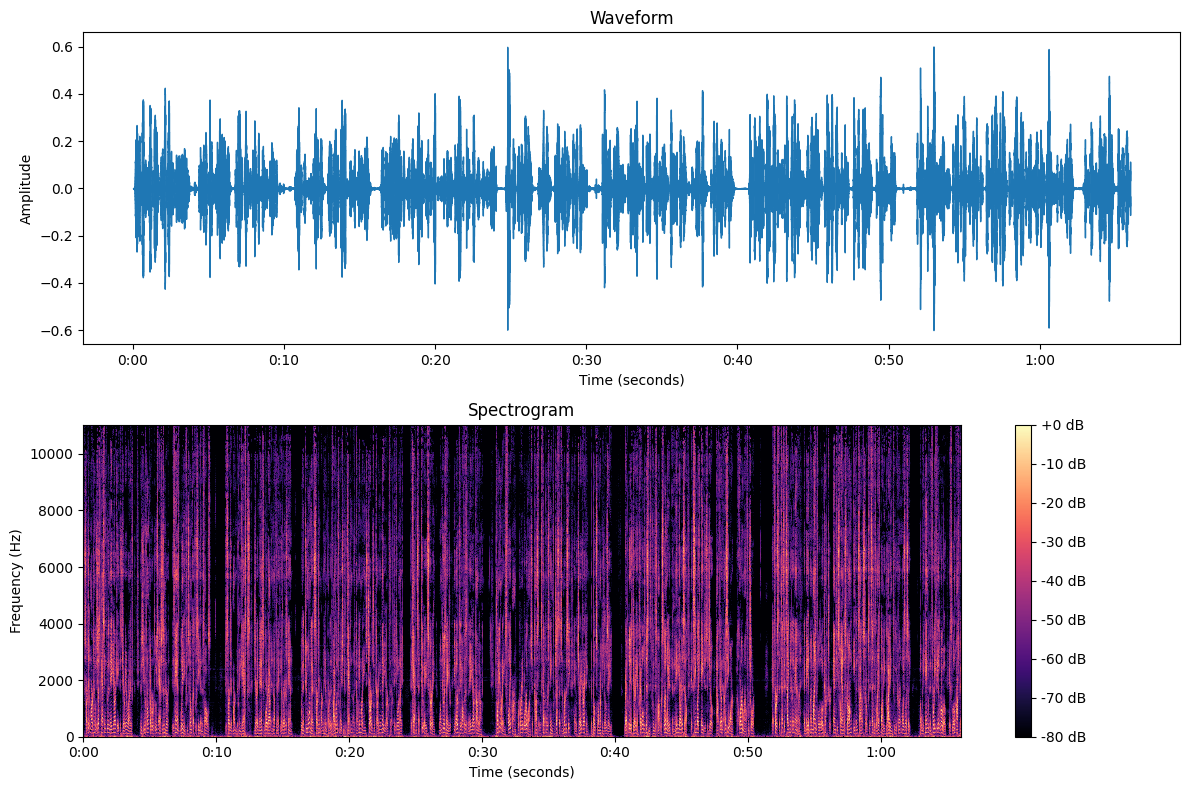

In [16]:
#audio preprocessing - View audio in waveform and spectrogram, the audio being preprocessed will carry over to the other preprocessing steps.

# Create waveform and spectrogram plots
plt.figure(figsize=(12, 8))

# Waveform
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

# Spectrogram
D = librosa.stft(y)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.subplot(2, 1, 2)
librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis="time",
    y_axis="hz"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

In [17]:
# audio preprocessing - trim leading/trailing silence

choice = input("Do you want to trim leading and trailing silence? (y/n): ")

if choice.lower() == "y":
    y_trimmed, _ = librosa.effects.trim(y, top_db=20)

    plt.figure(figsize=(10, 5))
    librosa.display.waveshow(y_trimmed, sr=sr)
    plt.title("Trimmed Audio Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

    print("Silence trimming complete!")

else:
    y_trimmed = y
    print("Skipping silence trimming.")

Skipping silence trimming.


In [18]:
#preprosessing - reduce background noise

choice = input("Do you want to reduce background noise? (y/n): ")

if choice.lower() == "y":
    y_denoised = nr.reduce_noise(y=y_trimmed, sr=sr)

    plt.figure(figsize=(10, 5))
    librosa.display.waveshow(y_denoised, sr=sr)
    plt.title("Noise-Reduced Audio Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

    print("Noise reduction complete!")

else:
    y_denoised = y_trimmed
    print("Skipping noise reduction.")

Skipping noise reduction.


In [19]:
# audio preprocessing - normalize loudness

choice = input("Do you want to normalize loudness? (y/n): ")

if choice.lower() == "y":
    # Measure the audio loudness
    meter = pyln.Meter(sr)
    loudness = meter.integrated_loudness(y_denoised)

    # Normalize the audio loudness to -23 LUFS
    y_normalized = pyln.normalize.loudness(
        y_denoised,
        loudness,
        -23.0
    )

    # Plot the normalized audio
    plt.figure(figsize=(10, 5))
    librosa.display.waveshow(y_normalized, sr=sr)
    plt.title("Loudness-Normalized Audio Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

    print("Loudness normalization complete!")

else:
    y_normalized = y_denoised
    print("Skipping loudness normalization.")

Skipping loudness normalization.


In [20]:
# Save the processed audio, whether preprocessing was applied or skipped

output_filename= Path(filename).stem + '_processed.wav'
output_file=f'audio/Processed/{output_filename}'

sf.write(output_file, y_normalized, sr)

print("Audio saved to:", output_file)

Audio saved to: audio/Processed/brightonboys_long_processed.wav
